# Lecture 1 · Guided practical: getting started and exploring Kigali Sentinel-2 data

**Machine Learning for Earth Observation · Year 3 · 45–60 minutes · work in pairs**

This first practical has two aims:
1. **Get started** with the tools used in every practical: Jupyter notebooks, the course conda environment, and basic Python/NumPy.
2. **Explore real EO data**: three Sentinel-2 Level-2A images of Kigali (21 January, 13 May and 3 September 2026).

| Part | What you do | Learning objectives | Time |
|---|---|---|---|
| 0 | Jupyter basics, environment check, a Python/NumPy warm-up | — | 10 min |
| 1 | Open the files: shape, data type, pixel size, extent, value ranges | raster data (LO3), quality (LO6) | 6 min |
| 2 | Band stack; true- and false-colour composites | multiband raster (LO3) | 6 min |
| 3 | Spectral signatures of five surface types | spectral characteristics (LO4) | 6 min |
| 4 | Degrade the spatial resolution: mixed pixels | resolution (LO2, LO5) | 6 min |
| 5 | Re-quantise to 8 bits: radiometric resolution | resolution (LO2) | 4 min |
| 6 | Compare three dates; mask clouds and no-data with the SCL | temporal resolution, quality (LO2, LO6) | 6 min |
| 7 | Build a small sample table: features x and label y | samples, features, labels (LO7) | 5 min |

Complete the cells marked **`# TODO`** (replace `...`) and write your answers in the **Your answer** boxes.

## Part 0 · Getting started

### 0.1 How a notebook works
* A notebook is a list of **cells**. *Markdown* cells (like this one) contain text; *code* cells contain Python.
* Run the selected cell with **Shift + Enter** (runs it and moves to the next cell). Ctrl + Enter runs it and stays.
* Cells share one Python session (the **kernel**). Variables created in one cell are available in later cells, **in the order you ran them**, not the order on the page.
* If something behaves strangely: *Kernel → Restart Kernel and Run All Cells…*
* `[*]` next to a cell means it is still running; a number, e.g. `[3]`, shows the order in which cells were run.
* Save often (Ctrl + S). Add your own notes in new Markdown cells (press **M** in command mode to turn a cell into Markdown).

### 0.2 Before you start (in a terminal / Anaconda Prompt)
```
conda activate ml4eo          # the course environment
cd path/to/ml4eo/L1_Practical # the images are in ml4eo/data/
jupyter lab                   # or: jupyter notebook
```
Check the kernel name at the top right of the notebook: it should be the `ml4eo` environment (e.g. *Python 3 (ml4eo)*).

### 0.3 Check your environment
Run the next cell. Every line should say **OK**. If a package is missing, see `GETTING_STARTED.md`.

In [1]:
import sys, os, importlib

print("Python", sys.version.split()[0], "|", sys.executable)
print("Working directory:", os.getcwd())
for pkg in ["numpy", "pandas", "matplotlib", "scipy", "sklearn", "skimage", "rasterio"]:
    try:
        m = importlib.import_module(pkg)
        print(f"  OK   {pkg:12s} {m.__version__}")
    except ImportError:
        print(f"  MISSING  {pkg}  ->  conda install -n ml4eo {pkg.replace('sklearn', 'scikit-learn').replace('skimage', 'scikit-image')}")

# course data: the GeoTIFFs in ml4eo/data (one folder up from this notebook)
DATA = "../../data" if os.path.isdir("../../data") else ("../data" if os.path.isdir("../data") else "data")
if os.path.isdir(DATA):
    tiffs = [f for f in os.listdir(DATA) if f.endswith(".tiff")]
    print(f"  OK   data folder with {len(tiffs)} image files (expect 48)")
    csv_ok = os.path.exists(f"{DATA}/kigali_training_polygons.csv")
    print(f"  {'OK  ' if csv_ok else 'MISSING'} kigali_training_polygons.csv")
else:
    print("  MISSING  the folder", os.path.abspath(DATA), "- put the images in ml4eo/data")

Python 3.13.5 | c:\Users\user\anaconda3\envs\learning_python\python.exe
Working directory: c:\Users\user\OneDrive\Documents\KIST\ML4EO\L0_L3_practicals\L1_Practical
  OK   numpy        2.3.3
  OK   pandas       2.3.2
  OK   matplotlib   3.10.6
  OK   scipy        1.16.3
  OK   sklearn      1.7.1
  OK   skimage      0.26.0
  OK   rasterio     1.4.3
  OK   data folder with 48 image files (expect 48)
  OK   kigali_training_polygons.csv


### 0.4 A five-minute Python / NumPy warm-up
EO images are handled as **NumPy arrays**: grids of numbers with a `shape` and a `dtype`. Run the cell and read the comments.

In [2]:
import numpy as np

a = np.array([[0.05, 0.08, 0.30],
              [0.04, 0.25, 0.32]])           # a tiny 2 x 3 'image' of reflectance values
print("shape:", a.shape, "| dtype:", a.dtype)  # (rows, columns)
print("row 0, column 2:", a[0, 2])            # indexing: [row, column], counting from 0
print("first row:", a[0, :])                  # slicing: ':' means 'all'
print("mean:", a.mean().round(3), "| max:", a.max())
print("values > 0.2:", a > 0.2)                # a Boolean 'mask' of the same shape
print("mean of those:", a[a > 0.2].mean().round(3))

red = np.array([0.05, 0.10, 0.04]); nir = np.array([0.30, 0.12, 0.03])
ndvi = (nir - red) / (nir + red)               # arithmetic works element by element
print("NDVI:", ndvi.round(2))

shape: (2, 3) | dtype: float64
row 0, column 2: 0.3
first row: [0.05 0.08 0.3 ]
mean: 0.173 | max: 0.32
values > 0.2: [[False False  True]
 [False  True  True]]
mean of those: 0.29
NDVI: [ 0.71  0.09 -0.14]


**Try it:** in the empty cell below, create an array `b` of shape (3, 4) filled with the value 0.1 (`np.full`), then print its shape and the sum of all its values.

In [3]:
# TODO: an array b of shape (3, 4) filled with 0.1; print its shape and the sum of its values
b = np.full((3, 4), 0.1)
print(b.shape, b.sum().round(2))

(3, 4) 1.2


## Step 1 · Open the files and inspect them  *(LO3, LO6)*

The Kigali images are **GeoTIFFs** exported from the Copernicus Browser: one file per band and date, in `ml4eo/data/`. All three dates were exported with the **same box and settings**: 20 m pixels in UTM zone 36S (EPSG:32736). We open them with **rasterio** (see also the notebook `L0_Data_Access/Explore_Images.ipynb`).

2026-01-21 : B01, B02, B03, B04, B05, B06, B07, B08, B09, B11, B12, B8A, NDVI, NDWI, Scene_classification_map_, True_color
2026-05-13 : B01, B02, B03, B04, B05, B06, B07, B08, B09, B11, B12, B8A, NDVI, NDWI, Scene_classification_map_, True_color
2026-09-03 : B01, B02, B03, B04, B05, B06, B07, B08, B09, B11, B12, B8A, NDVI, NDWI, Scene_classification_map_, True_color
B04: shape (1702, 2380), dtype float32, pixel 19.98 x 19.96 m, upper-left corner (163172, 9797058) m, EPSG:32736
B05: shape (1702, 2380), dtype float32, pixel 19.98 x 19.96 m, upper-left corner (163172, 9797058) m, EPSG:32736
B01: shape (1702, 2380), dtype float32, pixel 19.98 x 19.96 m, upper-left corner (163172, 9797058) m, EPSG:32736


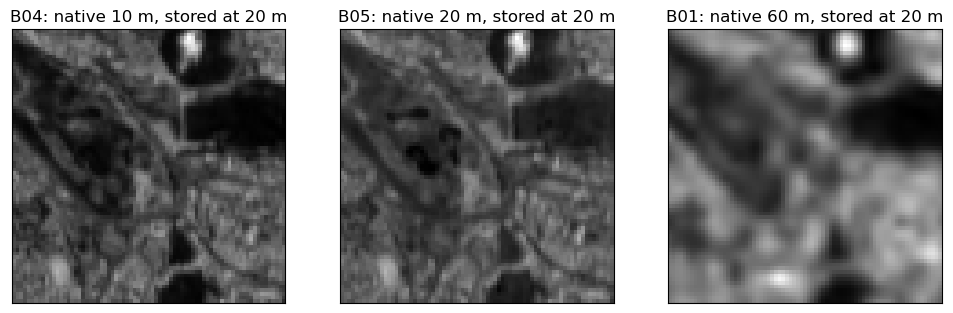

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

files = sorted(f for f in os.listdir(DATA) if f.endswith(".tiff"))    # one GeoTIFF per band and date
for date in ["2026-01-21", "2026-05-13", "2026-09-03"]:
    layers = [f.split("L2A_")[1].replace("_(Raw)", "").replace(".tiff", "") for f in files if f.startswith(date)]
    print(date, ":", ", ".join(layers))

SEP = f"{DATA}/2026-09-03-00_00_2026-09-03-23_59_Sentinel-2_L2A_"     # start of every September file name

# open three files with different NATIVE resolutions: 10 m (B04), 20 m (B05), 60 m (B01)
raw = {}
for b in ["B04", "B05", "B01"]:
    with rasterio.open(SEP + b + "_(Raw).tiff") as src:
        raw[b] = src.read(1)
        print(f"{b}: shape {raw[b].shape}, dtype {raw[b].dtype}, pixel {src.res[0]:.2f} x {src.res[1]:.2f} m, "
              f"upper-left corner ({src.bounds.left:.0f}, {src.bounds.top:.0f}) m, {src.crs}")

# zoom on 1.5 km x 1.5 km: the 60 m band looks blurred although it is stored with 20 m pixels
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (b, native) in zip(ax, [("B04", 10), ("B05", 20), ("B01", 60)]):
    a.imshow(raw[b][700:775, 600:675], cmap="gray"); a.set_title(f"{b}: native {native} m, stored at 20 m")
    a.set_xticks([]); a.set_yticks([])
plt.show()

All bands have the same shape, pixel size and corner: they are on **one grid**, so pixel (row, col) is the same place on the ground in every band and on every date. That was a choice made at export: Copernicus Browser **resampled** every band to 20 m. The 10 m bands lost detail, and the 60 m bands (B01, B09) were interpolated to 20 m: they look smooth and blurred, and they contain no more detail than before. The *stored* pixel size is not always the *real* resolution.

The files store reflectance (0–1). Many archives (for example the original Sentinel-2 SAFE products and Google Earth Engine) deliver integer **digital numbers (DN) = reflectance × 10,000** instead. To practise with that format, the next cell first stores the 12 bands as DN, the way such an archive would (`uint16`, 0 = no data). Your task is to convert them back to reflectance.

In [5]:
BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]
layers = []
for b in BANDS:
    with rasterio.open(SEP + b + "_(Raw).tiff") as src:
        layers.append(src.read(1))                 # reflectance 0-1, 0 = no data
        px_x, px_y = src.res                       # pixel size in metres (UTM)
        crs = src.crs
dn = np.round(np.stack(layers) * 10000).astype("uint16")   # store as DN, like an archive: (12 bands, rows, cols)
del layers
n_bands, H, W = dn.shape
print("shape (bands, rows, cols):", dn.shape, "| dtype:", dn.dtype)
print("DN range (valid pixels):", dn[dn > 0].min(), "-", dn.max(), "| no-data values (DN 0):", int((dn == 0).sum()))
print(f"memory: {dn.nbytes / 1e6:.1f} MB as uint16")

# UTM coordinates are in metres, so pixel size and extent can be read directly
print(f"pixel size {px_x:.2f} m x {px_y:.2f} m; extent {W * px_x / 1000:.1f} km x {H * px_y / 1000:.1f} km; CRS {crs}")

# TODO: convert DN to reflectance (reflectance = DN / 10000); use float32 and convert BEFORE any arithmetic
refl = dn.astype("float32") / 10000
refl[dn == 0] = np.nan                   # 0 = no data
s = {b: refl[i] for i, b in enumerate(BANDS)}
print("reflectance B08: min %.3f, median %.3f, max %.3f" % (np.nanmin(s["B08"]), np.nanmedian(s["B08"]), np.nanmax(s["B08"])))
print("pixels with reflectance > 1 (any band):", int(np.nansum(refl > 1)))

shape (bands, rows, cols): (12, 1702, 2380) | dtype: uint16
DN range (valid pixels): 45 - 16250 | no-data values (DN 0): 192972
memory: 97.2 MB as uint16
pixel size 19.98 m x 19.96 m; extent 47.5 km x 34.0 km; CRS EPSG:32736
reflectance B08: min 0.005, median 0.243, max 1.625
pixels with reflectance > 1 (any band): 13


**Question 1.** What are the dimensions, data type, pixel size and extent of the September stack? How does the pixel size compare with the native Sentinel-2 resolutions (10, 20, 60 m), and why? What does the value > 1 tell you?

*Your answer:*

The September stack has 12 bands × 1,702 rows × 2,380 columns, stored as `uint16` digital numbers (reflectance × 10,000), 97 MB in total. The pixels are 19.98 × 19.96 m and the area covers 47.5 × 34.0 km, in UTM zone 36S (EPSG:32736), so coordinates are in metres.

Every band was exported on one 20 m grid. That equals the native resolution of the red-edge and SWIR bands (B05–B07, B8A, B11, B12). It is coarser than the 10 m bands (B02–B04, B08), which lost detail, and finer than the 60 m bands (B01, B09), which were only interpolated and look blurred in the zoom. One common grid makes bands and dates comparable pixel by pixel, but the stored pixel size is not always the real resolution.

13 values have a reflectance > 1. That is physically implausible for a natural surface: very bright targets or processing artefacts. They should be checked or masked before machine learning.

## Step 2 · Band stack and colour composites  *(LO3)*

A colour image uses three bands as red, green and blue. We stretch each band between its 2nd and 98th percentile so that the image is not too dark.

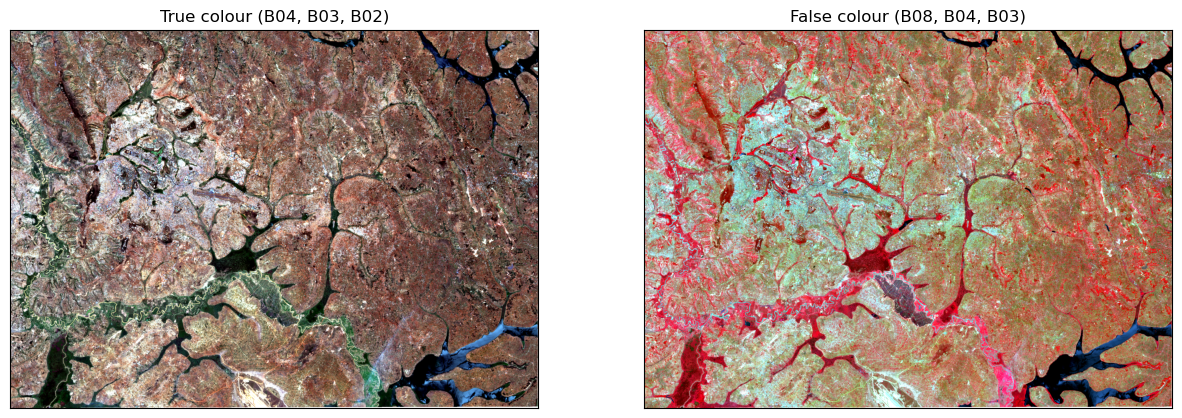

In [6]:
def stretch(a, lo=2, hi=98):
    l, h = np.nanpercentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1)

def composite(r, g, b):
    rgb = np.dstack([stretch(r), stretch(g), stretch(b)])
    rgb[np.isnan(rgb)] = 1                  # no data shown white
    return rgb

true_colour = composite(s["B04"], s["B03"], s["B02"])    # red, green, blue
# TODO: a standard false-colour composite: NIR (B08) as red, red (B04) as green, green (B03) as blue
false_colour = composite(s["B08"], s["B04"], s["B03"])   # NIR, red, green
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(true_colour); ax[0].set_title("True colour (B04, B03, B02)")
ax[1].imshow(false_colour); ax[1].set_title("False colour (B08, B04, B03)")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()

**Question 2.** In the false-colour image, what colour are vegetation, water and the city? Why is vegetation so much brighter in this composite than in true colour?

*Your answer:*

False colour (NIR, red, green shown as R, G, B): vegetation is bright red, water is dark (nearly black with a blue tint), and the city and bare soil are grey to tan/brown.

Healthy leaves reflect strongly in the near infrared (about 0.29 for dense vegetation, against 0.05 in the red). NIR is displayed in the red channel, so vegetation dominates the picture. In true colour, vegetation is only slightly brighter in green than in the other visible bands, so it looks dark.

## Step 3 · Spectral signatures of five surface types  *(LO4)*

`kigali_training_polygons.csv` lists 1,225 pixels (row, column) inside 49 polygons of five classes. We read the 12 reflectances at these pixels and average them per class.

   obs_id group_id  class   row   col         x          y        lon       lat  block_id
0       1   poly_1  water  1456  1959  202315.3  9767987.8  30.323907 -2.096842       705
1       2   poly_1  water  1456  1960  202335.3  9767987.8  30.324206 -2.096842       705
2       3   poly_1  water  1456  1962  202375.3  9767987.8  30.324504 -2.096842       705
class
dense vegetation     300
built-up             300
sparse vegetation    225
water                200
bare soil            200
Name: count, dtype: int64


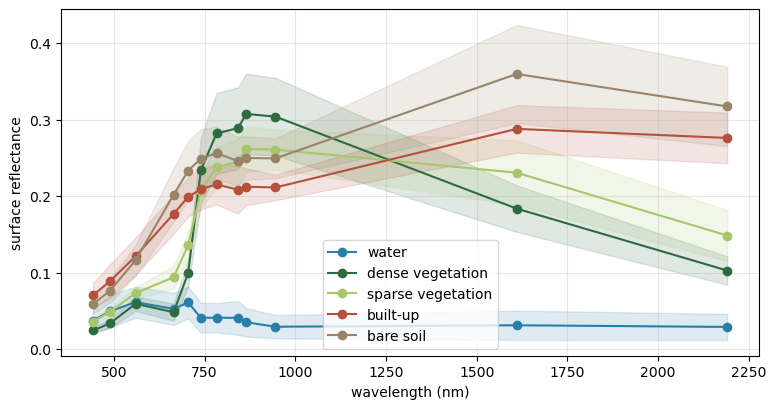

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B11,B12
class,,,,,,,,,,,,
bare soil,0.059,0.077,0.116,0.202,0.233,0.249,0.256,0.246,0.250,0.249,0.360,0.317
built-up,0.071,0.089,0.121,0.177,0.199,0.209,0.215,0.208,0.212,0.211,0.288,0.276
dense vegetation,0.024,0.034,0.059,0.048,0.100,0.234,0.282,0.289,0.307,0.304,0.184,0.103
sparse vegetation,0.036,0.049,0.073,0.094,0.136,0.207,0.238,0.245,0.262,0.261,0.231,0.149
water,0.037,0.050,0.061,0.053,0.061,0.041,0.041,0.041,0.035,0.029,0.031,0.029


In [7]:
poly = pd.read_csv(f"{DATA}/kigali_training_polygons.csv")
print(poly.head(3)); print(poly["class"].value_counts())
r, c = poly["row"].values, poly["col"].values
for b in BANDS:
    poly[b] = s[b][r, c]                      # the reflectance of band b at every sample pixel

WAVELENGTH = [443, 490, 560, 665, 705, 740, 783, 842, 865, 945, 1610, 2190]   # nm, band centres
CC = {"water": "#2A7FA8", "dense vegetation": "#2E6B3F", "sparse vegetation": "#A8C66C", "built-up": "#B5503C", "bare soil": "#9A8468"}
# TODO: mean and standard deviation of each band per class (hint: poly.groupby("class")[BANDS].mean())
means = poly.groupby("class")[BANDS].mean()
sds = poly.groupby("class")[BANDS].std()
plt.figure(figsize=(9, 4.5))
for cls in CC:
    plt.plot(WAVELENGTH, means.loc[cls], "o-", color=CC[cls], label=cls)
    plt.fill_between(WAVELENGTH, means.loc[cls] - sds.loc[cls], means.loc[cls] + sds.loc[cls], color=CC[cls], alpha=0.15)
plt.xlabel("wavelength (nm)"); plt.ylabel("surface reflectance"); plt.legend(); plt.grid(alpha=0.3); plt.show()
means.round(3)

**Question 3.** Which bands best separate (a) water from everything else, (b) vegetation from non-vegetation, (c) dense from sparse vegetation? Which pair of classes is hardest to separate, and why?

*Your answer:*

(a) Water: it is darkest in the NIR and SWIR (B08, B8A, B11, B12 ≈ 0.03–0.04), while every land class is ≥ 0.10 in these bands.

(b) Vegetation vs non-vegetation: red (B04, low for vegetation: 0.05) against NIR and red edge (B06–B8A, high: 0.23–0.31).

(c) Dense vs sparse vegetation: red (0.048 vs 0.094) and especially the SWIR bands (B12: 0.103 vs 0.149; B11: 0.184 vs 0.231). Dense canopies hold more leaf water and show less soil.

The hardest pair is bare soil vs built-up. Their spectra have the same shape (rising towards the SWIR) and their ±1 SD envelopes overlap in almost every band, because they share materials: red soil, laterite roads, clay tiles, construction sites.

### The scene classification layer (SCL)

Steps 4–7 use the **scene classification layer**, which gives each pixel a code: 4 = vegetation, 5 = not vegetated, 6 = water, 8/9 = cloud, 10 = thin cirrus, and so on. The Copernicus Browser exports it as a **coloured picture** (3 layers: red, green, blue), so we turn each colour back into its code. We write this as a small function because we need it again in Step 6. (The notebook `Explore_Images.ipynb` shows the picture itself.)

In [8]:
SCL_COLOURS = {0: (0, 0, 0), 1: (255, 0, 0), 2: (47, 47, 47), 3: (100, 50, 0), 4: (0, 160, 0), 5: (255, 230, 90),
               6: (0, 0, 255), 7: (128, 128, 128), 8: (192, 192, 192), 9: (255, 255, 255), 10: (100, 200, 255), 11: (255, 150, 255)}

def read_scl(date):
    # Read the SCL picture of one date and return a 2-D array of class codes
    path = f"{DATA}/{date}-00_00_{date}-23_59_Sentinel-2_L2A_Scene_classification_map_.tiff"
    with rasterio.open(path) as src:
        rgb = np.round(src.read() * 255)             # 3 layers of colour values 0-255
    codes = np.zeros(rgb.shape[1:], dtype=np.uint8)   # start with 0 (no data) everywhere
    for code_, (r, g, b) in SCL_COLOURS.items():
        codes[(rgb[0] == r) & (rgb[1] == g) & (rgb[2] == b)] = code_
    return codes

scl = read_scl("2026-09-03")
print("SCL codes found in September:", np.unique(scl))

SCL codes found in September: [ 0  2  4  5  6  7  8 10]


## Step 4 · Spatial resolution: what happens with bigger pixels?  *(LO2, LO5)*

We simulate coarser sensors by averaging blocks of *f × f* pixels (f = 5 → 100 m, 15 → 300 m, 50 → 1 km). For each coarse pixel we also check how *pure* it is using the scene classification layer (SCL: 4 = vegetation, 5 = not vegetated, 6 = water).

water at the original 20 m: 2.35% of pixels


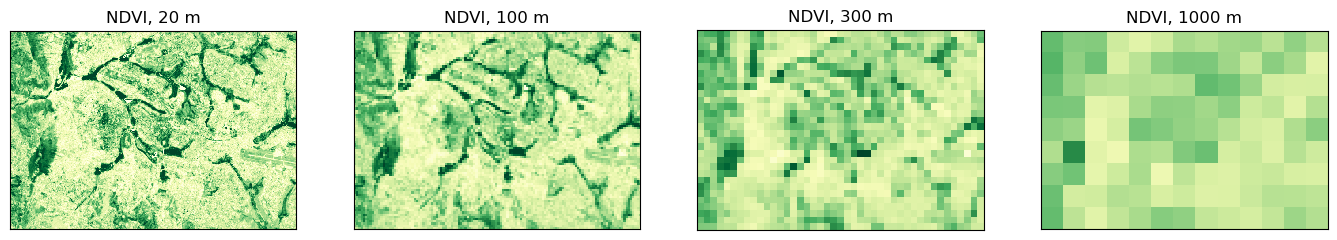

,pixel size (m),coarse pixels,% ≥ 90% one class,% strongly mixed (< 60%),% water (majority)
0,100,161840,61.3,7.4,2.4
1,300,17854,46.5,10.5,2.3
2,1000,1598,30.3,12.0,1.9


In [9]:
import warnings
warnings.filterwarnings("ignore", message="Mean of empty slice")   # coarse pixels in the no-data frame
ndvi = (s["B08"] - s["B04"]) / (s["B08"] + s["B04"])

def blocks(a, f):
    """Cut array a into non-overlapping f x f blocks: result shape (rows/f, cols/f, f*f)."""
    h, w = (a.shape[0] // f) * f, (a.shape[1] // f) * f
    return a[:h, :w].reshape(h // f, f, w // f, f).transpose(0, 2, 1, 3).reshape(h // f, w // f, f * f)

rows, coarse = [], {1: ndvi}
for f in [5, 15, 50]:
    b = blocks(scl, f)
    share = np.stack([(b == k).mean(axis=-1) for k in [4, 5, 6]])      # share of each SCL class per coarse pixel
    purity = share.max(axis=0)
    # TODO: the coarse NDVI = mean of each f x f block (use blocks() and np.nanmean over the last axis)
    coarse[f] = blocks(ndvi, f).mean(axis=-1)
    rows.append({"pixel size (m)": int(round(f * px_x, -1)), "coarse pixels": purity.size,
                 "% ≥ 90% one class": 100 * (purity >= 0.9).mean(), "% strongly mixed (< 60%)": 100 * (purity < 0.6).mean(),
                 "% water (majority)": 100 * (share[2] > 0.5).mean()})
print(f"water at the original 20 m: {100 * (scl == 6).mean():.2f}% of pixels")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.5))
zoom = (slice(450, 900), slice(300, 950))          # central Kigali
for a, f in zip(ax, [1, 5, 15, 50]):
    z = coarse[f][zoom[0].start // f:zoom[0].stop // f, zoom[1].start // f:zoom[1].stop // f]
    a.imshow(z, cmap="YlGn", vmin=0, vmax=0.7, interpolation="nearest"); a.set_title(f"NDVI, {int(round(f * px_x, -1))} m"); a.set_xticks([]); a.set_yticks([])
plt.show()
pd.DataFrame(rows).round(1)

**Question 4.** What happens to the share of pure pixels and to the small water bodies as pixels get larger? For which of these tasks would 1 km pixels be acceptable: (a) mapping Kigali's built-up area, (b) monitoring seasonal greenness of Rwanda as a whole?

*Your answer:*

As the pixels grow, the share of pure pixels (≥ 90% one SCL class) falls from 61% at 100 m to 47% at 300 m and 30% at 1 km, while strongly mixed pixels rise from 7% to 12%. Water is 2.35% of the 20 m pixels and still about 1.9% of the 1 km pixels, because most water here lies in large lakes. What is lost are the shores, narrow rivers and small ponds, which become mixed pixels.

(a) Mapping Kigali's built-up area: 1 km is not acceptable. Houses and roads are 5–20 m wide, so almost every 1 km pixel would be mixed.
(b) Monitoring the seasonal greenness of Rwanda as a whole: yes, 1 km is acceptable. It is a regional question and daily 250 m – 1 km data (MODIS/VIIRS) are appropriate.

## Step 5 · Radiometric resolution: 8 bits vs the original  *(LO2)*

Sentinel-2 records 12-bit data (4,096 levels). What if we stored reflectance with only 8 bits (256 levels), like a JPEG screenshot?

In [10]:
def quantise(a, bits):
    levels = 2 ** bits - 1
    # TODO: clip a to 0-1, scale to 0..levels, round to whole numbers, and scale back to 0-1
    return np.round(np.clip(a, 0, 1) * levels) / levels

water, veg = (scl == 6), (scl == 4)
rows = []
for bits in [8, 10, 12]:
    r8, n8 = quantise(s["B04"], bits), quantise(s["B08"], bits)
    ndvi_q = (n8 - r8) / (n8 + r8)
    err = ndvi_q - ndvi
    rows.append({"bits": bits, "levels": 2 ** bits, "distinct red values over water": len(np.unique(r8[water])),
                 "NDVI RMSE water": np.sqrt(np.nanmean(err[water] ** 2)), "NDVI RMSE vegetation": np.sqrt(np.nanmean(err[veg] ** 2))})
print("distinct red values over water in the original data:", len(np.unique(s["B04"][water])))
pd.DataFrame(rows).round(4)

distinct red values over water in the original data: 1012


,bits,levels,distinct red values over water,NDVI RMSE water,NDVI RMSE vegetation
0,8,256,38,0.0308,0.0055
1,10,1024,127,0.0075,0.0014
2,12,4096,445,0.0019,0.0003


**Question 5.** Why does 8-bit storage hurt NDVI over water much more than over vegetation? What does this imply for using screenshots or JPEG images for analysis?

*Your answer:*

Water is dark (mean red reflectance ≈ 0.05), so its values fall into very few of the 256 levels: only 38 distinct red values remain over water, against 1,012 in the original data. NDVI is a ratio of differences between small numbers, so the rounding error is amplified: the NDVI RMSE over water is 0.031, against 0.0055 over vegetation at 8 bits (0.0019 and 0.0003 at 12 bits).

Screenshots and JPEGs (8 bits, often compressed and stretched for display) are fine for looking at an image, but not for computing indices or training models. Always use the original data values.

## Step 6 · Three dates and data quality  *(LO2, LO6)*

21 January and 13 May 2026 were exported with the same box and settings as September, so all three dates share one grid and can be compared pixel by pixel. We load only the four bands we need. SCL codes: 0 no data, 3 cloud shadow, 4 vegetation, 5 not vegetated, 6 water, 8/9 cloud, 10 thin cirrus.

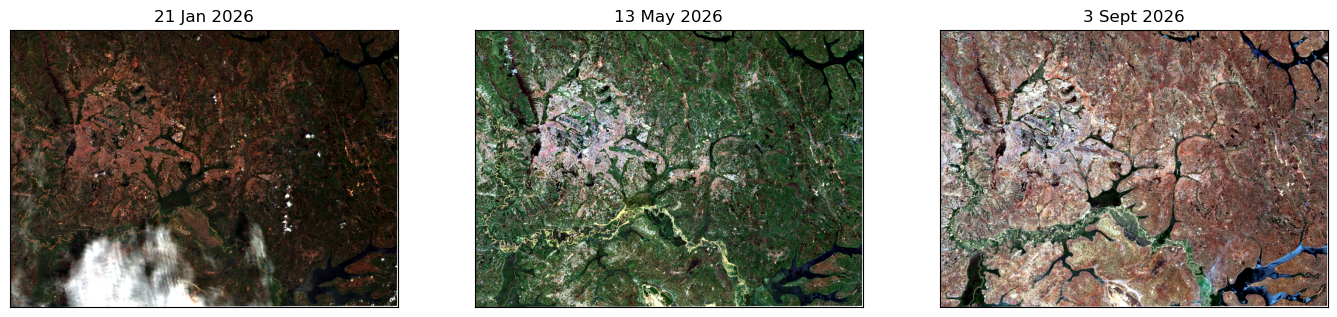

,21 Jan 2026,13 May 2026,3 Sept 2026
cloud (high),0.27,0.00,0.00
cloud (medium),3.95,0.01,0.01
cloud shadow,0.21,0.09,0.00
dark area,0.05,0.04,0.05
no data,0.40,0.40,0.40
not vegetated,19.32,14.04,76.24
thin cirrus,2.36,0.00,0.65
unclassified,0.77,0.21,0.29
vegetation,70.36,82.44,20.01
water,2.31,2.76,2.35


In [11]:
dates = {"21 Jan 2026": "2026-01-21", "13 May 2026": "2026-05-13", "3 Sept 2026": "2026-09-03"}
SCL_NAMES = {0: "no data", 2: "dark area", 3: "cloud shadow", 4: "vegetation", 5: "not vegetated", 6: "water", 7: "unclassified", 8: "cloud (medium)", 9: "cloud (high)", 10: "thin cirrus"}

scl_d, rgb_d, ndvi_d = {}, {}, {}
for label, key in dates.items():
    if key == "2026-09-03":
        b = {k: s[k] for k in ["B02", "B03", "B04", "B08"]}; sc = scl       # already loaded
    else:
        b = {}
        for band in ["B02", "B03", "B04", "B08"]:
            path = f"{DATA}/{key}-00_00_{key}-23_59_Sentinel-2_L2A_{band}_(Raw).tiff"
            with rasterio.open(path) as src:
                a = src.read(1)
            a[a == 0] = np.nan                                        # 0 = no data
            b[band] = a
        sc = read_scl(key)
    scl_d[label] = sc
    rgb_d[label] = composite(b["B04"], b["B03"], b["B02"])
    ndvi_d[label] = (b["B08"] - b["B04"]) / (b["B08"] + b["B04"])

shares = pd.DataFrame({label: pd.Series(sc.ravel()).map(SCL_NAMES).value_counts(normalize=True) * 100 for label, sc in scl_d.items()}).fillna(0).round(2)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (label, im) in zip(ax, rgb_d.items()):
    a.imshow(im); a.set_title(label); a.set_xticks([]); a.set_yticks([])
plt.show()
shares

Now build a **validity mask** for each date: keep only vegetation, not vegetated and water (SCL 4, 5, 6), and compare the median NDVI of pixels that are valid on all three dates.

In [12]:
# TODO: for each date, a Boolean mask that is True where the SCL is 4, 5 or 6 (hint: np.isin) AND NDVI is finite
valid = {label: np.isin(sc, [4, 5, 6]) & np.isfinite(ndvi_d[label]) for label, sc in scl_d.items()}
common = valid["21 Jan 2026"] & valid["13 May 2026"] & valid["3 Sept 2026"]
print(f"pixels valid on all three dates: {100 * common.mean():.1f}% of the grid")
for label in dates:
    print(f"  {label}: {100 * valid[label].mean():5.1f}% valid | median NDVI (common pixels) = {np.nanmedian(ndvi_d[label][common]):.2f}")

pixels valid on all three dates: 91.1% of the grid
  21 Jan 2026:  92.0% valid | median NDVI (common pixels) = 0.61
  13 May 2026:  99.2% valid | median NDVI (common pixels) = 0.67
  3 Sept 2026:  98.6% valid | median NDVI (common pixels) = 0.32


**Question 6.** (a) Which data-quality problems do you see in the January image (look at the pictures and the SCL table)? (b) What share of the pixels is valid on all three dates, and what removes the rest? (c) How and why does the median NDVI change between the dates, and what does that mean for a classifier trained on the September image?

*Your answer:*

(a) January has a cloud bank in the south-west: medium-probability cloud 3.95% of the grid, high-probability cloud 0.27%, thin cirrus 2.36% and cloud shadow 0.21%. The bright cloud also stretches the colour scale and makes the true-colour picture look darker. The SCL masks the cloud cores, but hazy margins may remain. All three dates also have a thin no-data frame at the edge (0.40%).

(b) 91.1% of the pixels are valid on all three dates. The rest is lost mainly to the January cloud, cirrus and shadow (January is 92.0% valid, against 99.2% in May and 98.6% in September), plus the no-data frame and a few unclassified pixels.

(c) The median NDVI of the common pixels is 0.61 in January and 0.67 in May, but only 0.32 in September: many fields and grasslands are green in the wetter months and bare or dry in September. A classifier trained on the September image learns September land cover. Applied to January it would call many areas 'vegetation' that look like 'bare soil' in September. Labels and images must refer to the same date.

## Step 7 · From pixels to an ML table: samples, features and labels  *(LO7)*

Each **sample** is one pixel; its **features x** are band values (and NDVI); its **label y** is the class of its polygon. We build the table and save it; Lecture 2 uses this kind of table to train a model.

In [13]:
FEATURES = ["B02", "B03", "B04", "B08", "B11", "B12"]
samples = poly[["obs_id", "group_id", "row", "col", "class"]].copy()
for f in FEATURES:
    # TODO: the value of band f at each sample's row and column
    samples[f] = s[f][samples["row"], samples["col"]]
samples["NDVI"] = ndvi[samples["row"], samples["col"]]
samples["SCL"] = scl[samples["row"], samples["col"]]
print(samples.shape)
print(samples.head())
print("\nSamples per class:"); print(samples["class"].value_counts())
print("\nSCL code of the samples, per class:"); print(pd.crosstab(samples["class"], samples["SCL"]))
samples.to_csv("kigali_samples_L1.csv", index=False)
print("saved kigali_samples_L1.csv")

(1225, 13)
   obs_id group_id   row   col  class     B02     B03     B04     B08     B11     B12      NDVI  SCL
0       1   poly_1  1456  1959  water  0.0965  0.1042  0.0932  0.0870  0.0689  0.0630 -0.034406    6
1       2   poly_1  1456  1960  water  0.0938  0.1010  0.0919  0.0806  0.0686  0.0631 -0.065507    6
2       3   poly_1  1456  1962  water  0.0938  0.1017  0.0916  0.0832  0.0682  0.0624 -0.048055    6
3       4   poly_1  1456  1964  water  0.0876  0.0961  0.0869  0.0781  0.0646  0.0594 -0.053333    6
4       5   poly_1  1456  1965  water  0.0873  0.0936  0.0853  0.0775  0.0632  0.0570 -0.047912    6

Samples per class:
class
dense vegetation     300
built-up             300
sparse vegetation    225
water                200
bare soil            200
Name: count, dtype: int64

SCL code of the samples, per class:
SCL                  4    5    6   7
class                               
bare soil            0  200    0   0
built-up             0  300    0   0
dense vegetation   30

**Question 7.** In this table, what is one sample, what are the features and what is the label? The 1,225 pixels come from only 49 polygons: why might that matter? Compare the class labels with the SCL codes: where do they disagree, and why can both be 'right'?

*Your answer:*

One sample is one 20 m pixel. The features x are the six reflectances B02, B03, B04, B08, B11, B12 and NDVI. The label y is the class of the polygon the pixel lies in.

The 1,225 pixels come from only 49 polygons (25 pixels each), and neighbouring pixels are very similar. The table holds far less independent information than 1,225 separate observations, which matters for validation: pixels of the same polygon must not be split between training and test data (Lecture 4).

Labels and SCL disagree for sparse vegetation (124 pixels are SCL 'vegetation', 101 'not vegetated') and for 25 water pixels (SCL 'unclassified'). Both can be 'right' because they use different definitions. The SCL is a generic automatic classification with fixed thresholds; our legend separates dense from sparse vegetation and was defined by us, and a sparse-vegetation pixel lies near the SCL's vegetation threshold.

## Reflection (submit in pairs)

1. Write down three facts about the Kigali data you would put in the *Data* section of a report (sensor, level, date, pixel size, extent, bands, quality).
2. Name one data-quality check from today you will always do before training a model, and why.
3. Which of the four resolutions limited today's analysis most? Explain with one result from this notebook.

*Your answer:*

1. **Data section:** Sentinel-2 MSI Level-2A surface reflectance, acquired on 3 September 2026 (plus 21 January and 13 May 2026), exported from the Copernicus Browser. 12 bands on one 20 m grid in UTM zone 36S (EPSG:32736); 2,380 × 1,702 pixels = 47.5 × 34.0 km around Kigali; reflectance 0–1, 0 = no data. In September 98.6% of the pixels are valid (thin cirrus 0.65%) and 13 values are > 1.

2. **Check I will always do:** look at the value ranges and apply the SCL mask before extracting features. Clouds, no-data and out-of-range values become extreme feature values and wrong labels, and they silently damage the model.

3. **Most limiting resolution:** the spatial resolution. At 20 m many urban pixels are mixed and houses are sub-pixel (only 61% of the 100 m pixels are pure), and the 60 m bands are even coarser. The temporal dimension also matters: the September date makes seasonal fields look like bare soil (median NDVI 0.32 against 0.61–0.67).